In [ ]:
# 1. Install packages (Google Colab)
!pip -q install rasterio pandas matplotlib numpy


In [ ]:
# 2. Upload exactly three TIFF files in Colab.
# If files are already under /content, skip the upload.
from pathlib import Path
from google.colab import files
uploaded = files.upload()

files_present = list(Path('/content').glob('*.tif'))
print('Available TIFFs:', [p.name for p in files_present])


Available TIFFs: ['ndvi_rangpur.tif', 'dem_rangpur.tif', 'ndwi_rangpur.tif']


In [ ]:
# 3. Identify input TIFF files, including names with (1) suffixes.
from pathlib import Path
import numpy as np, pandas as pd, rasterio, matplotlib.pyplot as plt
from rasterio.warp import reproject, Resampling
from rasterio.plot import plotting_extent
from matplotlib.colors import ListedColormap
from IPython.display import display
import zipfile

all_tifs = list(Path('/content').glob('*.tif'))
def find_one(token):
    candidates = [p for p in all_tifs if p.name.lower().startswith(token) and p.suffix.lower()=='.tif']
    if len(candidates) != 1:
        raise ValueError(f'Expected exactly one {token}*.tif; found: {candidates}')
    return candidates[0]

DEM_PATH = find_one('dem_rangpur')
NDVI_PATH = find_one('ndvi_rangpur')
NDWI_PATH = find_one('ndwi_rangpur')
OUT = Path('/content/rangpur_three_raster_outputs')
OUT.mkdir(exist_ok=True)
print('Selected:', DEM_PATH.name, NDVI_PATH.name, NDWI_PATH.name)


Selected: dem_rangpur.tif ndvi_rangpur.tif ndwi_rangpur.tif


In [ ]:
# 4. Check file metadata and build aligned arrays on the NDVI grid.
# Mask alignment: intersection of valid NDVI and NDWI pixels and finite DEM pixels.
with rasterio.open(NDVI_PATH) as ndvi_src, \
     rasterio.open(NDWI_PATH) as ndwi_src, \
     rasterio.open(DEM_PATH) as dem_src:

    for name, src in [('DEM',dem_src),('NDVI',ndvi_src),('NDWI',ndwi_src)]:
        print(name,'CRS',src.crs, 'shape',src.shape, 'resolution',src.res,
              'nodata',src.nodata, 'bounds',src.bounds)
    assert ndvi_src.crs and ndwi_src.crs and dem_src.crs, 'Missing CRS metadata'

    template_shape = (ndvi_src.height, ndvi_src.width)
    transform = ndvi_src.transform
    crs = ndvi_src.crs
    bounds = ndvi_src.bounds

    def to_template(src, method=Resampling.nearest):
        dest = np.full(template_shape, np.nan, dtype='float32')
        reproject(source=rasterio.band(src,1), destination=dest,
                  src_transform=src.transform, src_crs=src.crs,
                  src_nodata=src.nodata,
                  dst_transform=transform, dst_crs=crs,
                  dst_nodata=np.nan, resampling=method)
        return dest

    ndvi = to_template(ndvi_src,Resampling.nearest)
    ndwi = to_template(ndwi_src,Resampling.nearest)
    elevation = to_template(dem_src,Resampling.nearest)

valid = np.isfinite(ndvi) & np.isfinite(ndwi) & np.isfinite(elevation)
# Screening: DEM zeros may be unmapped/background because its source has no NoData.
# Do not automatically remove all 0m values; inspect their location and provenance.
print('Common valid pixels:', int(valid.sum()))
print('DEM zeros inside common footprint:', int(np.count_nonzero((elevation==0)&valid)))
assert valid.sum() > 0, 'The three rasters have no overlapping valid area.'


DEM CRS EPSG:32645 shape (2545, 2103) resolution (29.518256217290332, 29.518256217290322) nodata None bounds BoundingBox(left=693014.5829418243, bottom=2799586.685876767, right=755091.4757667859, top=2874710.647949771)
NDVI CRS EPSG:32645 shape (2460, 2030) resolution (30.0, 30.0) nodata -3.4028234663852886e+38 bounds BoundingBox(left=693435.0, bottom=2800185.0, right=754335.0, top=2873985.0)
NDWI CRS EPSG:32645 shape (2460, 2030) resolution (30.0, 30.0) nodata -3.4028234663852886e+38 bounds BoundingBox(left=693435.0, bottom=2800185.0, right=754335.0, top=2873985.0)
Common valid pixels: 2626805
DEM zeros inside common footprint: 1966


In [ ]:
# 5. Descriptive statistics — COMMON footprint (not automatically the complete district).
rows=[]
for name, arr in [('Elevation (m)',elevation),('NDWI',ndwi),('NDVI',ndvi)]:
    vals=arr[valid]
    rows.append(dict(variable=name,valid_pixels=int(len(vals)),mean=float(np.mean(vals)),
                     median=float(np.median(vals)),p25=float(np.percentile(vals,25)),
                     p75=float(np.percentile(vals,75)),minimum=float(np.min(vals)),
                     maximum=float(np.max(vals))))
summary=pd.DataFrame(rows)
display(summary.round(4))
summary.to_csv(OUT/'environmental_summary.csv',index=False)

# Area estimate counts 30m pixels, valid only; may exclude water/vegetation data gaps.
pixel_area_km2 = abs(transform.a * transform.e) / 1_000_000
print('Valid common footprint:',round(valid.sum()*pixel_area_km2,2),'km²')


,variable,valid_pixels,mean,median,p25,p75,minimum,maximum
0,Elevation (m),2626805,32.1528,32.0000,29.0000,36.0000,0.0000,73.0000
1,NDWI,2626805,-0.3156,-0.3320,-0.3549,-0.2940,-0.4645,0.0681
2,NDVI,2626805,0.3549,0.3741,0.3299,0.3998,-0.0474,0.5252


Valid common footprint: 2364.12 km²


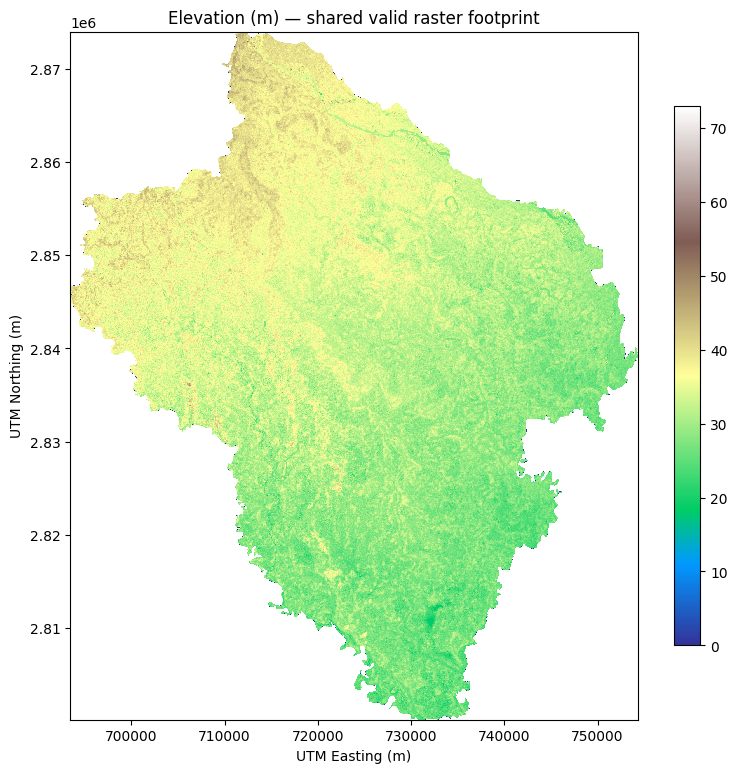

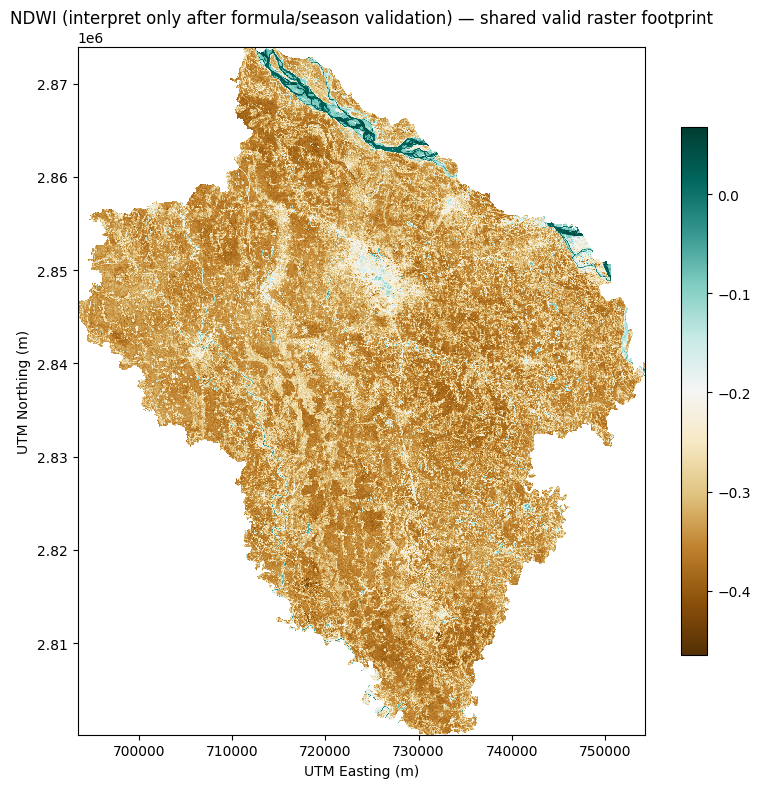

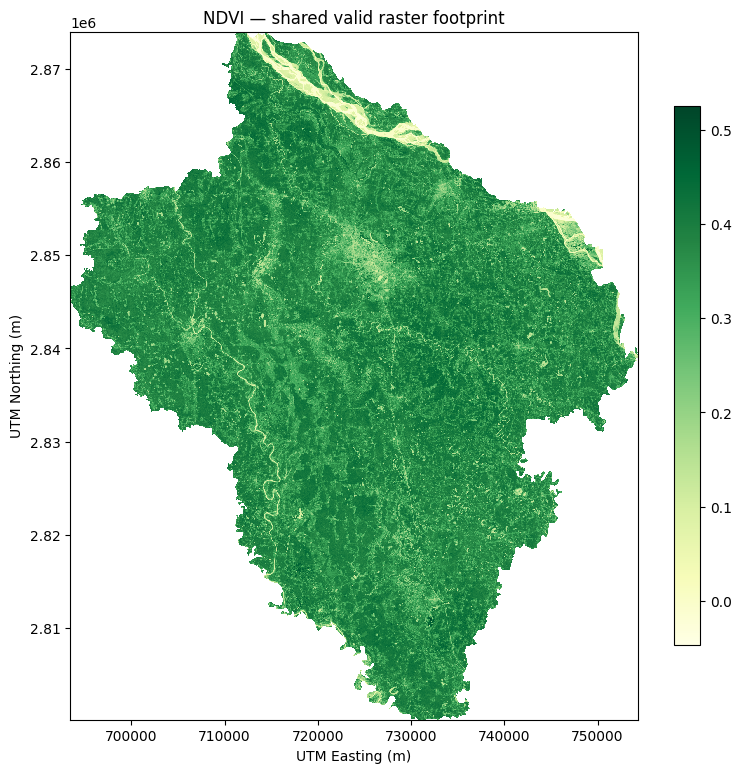

In [ ]:
# 6. Maps of all three input indicators in the common footprint.
extent=(bounds.left,bounds.right,bounds.bottom,bounds.top)
layers=[('Elevation (m)',elevation,'terrain','modern_elevation.png'),
        ('NDWI (interpret only after formula/season validation)',ndwi,'BrBG','modern_ndwi.png'),
        ('NDVI',ndvi,'YlGn','modern_ndvi.png')]
for title,arr,cmap,filename in layers:
    fig,ax=plt.subplots(figsize=(8,8))
    image=ax.imshow(np.ma.masked_where(~valid,arr),extent=extent,
                    origin='upper',cmap=cmap,interpolation='nearest')
    fig.colorbar(image,ax=ax,shrink=.75)
    ax.set_title(title+' — shared valid raster footprint')
    ax.set_xlabel('UTM Easting (m)');ax.set_ylabel('UTM Northing (m)')
    ax.set_aspect('equal')
    fig.tight_layout();fig.savefig(OUT/filename,dpi=180);plt.show()


Low elevation <= 29.0 m
Relatively high NDWI >= -0.294
Overlap pixels: 154346 area (km²): 138.91


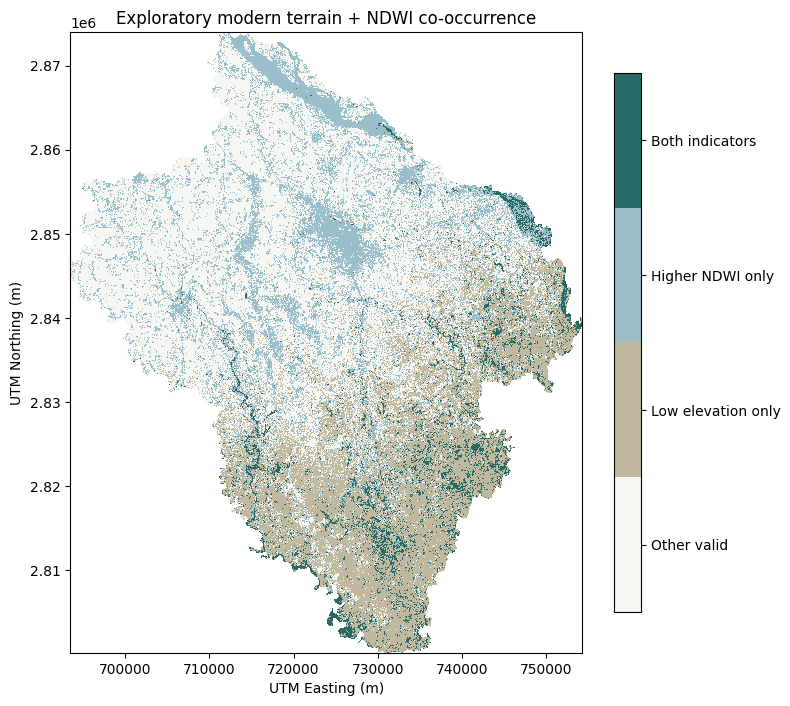

In [ ]:
# 7. Exploratory co-occurrence of low elevation and relatively high NDWI.
# Relative quantiles are NOT proof of wetlands, paleo-rivers, settlement suitability or malaria.
low_cut = float(np.quantile(elevation[valid],.25))
water_cut = float(np.quantile(ndwi[valid],.75))
low = valid & (elevation <= low_cut)
high_ndwi = valid & (ndwi >= water_cut)
both = low & high_ndwi
print('Low elevation <=',round(low_cut,3),'m')
print('Relatively high NDWI >=',round(water_cut,4))
print('Overlap pixels:',int(both.sum()),'area (km²):',round(both.sum()*pixel_area_km2,2))
classes=np.zeros(template_shape,dtype='uint8')
classes[low]=1;classes[high_ndwi]=2;classes[both]=3
classes=np.ma.masked_where(~valid,classes)
fig,ax=plt.subplots(figsize=(8,8))
cm=ListedColormap(['#f6f6f2','#c1b8a0','#9bbfca','#286b66'])
im=ax.imshow(classes,extent=extent,origin='upper',cmap=cm,vmin=-.5,vmax=3.5,
             interpolation='nearest')
cb=fig.colorbar(im,ax=ax,ticks=[0,1,2,3],shrink=.75)
cb.ax.set_yticklabels(['Other valid','Low elevation only','Higher NDWI only','Both indicators'])
ax.set_title('Exploratory modern terrain + NDWI co-occurrence')
ax.set_xlabel('UTM Easting (m)');ax.set_ylabel('UTM Northing (m)')
ax.set_aspect('equal');fig.tight_layout()
fig.savefig(OUT/'modern_low_elevation_high_ndwi_overlap.png',dpi=180);plt.show()


In [ ]:
# 8. 1-km grid summary: about 33x33 image pixels per grid, aligned to raster.
# Each grid value represents contemporary raster data only.
px = abs(transform.a)
py = abs(transform.e)
step_rows=max(1,round(1000/py)); step_cols=max(1,round(1000/px))
grid=[]
for r in range(0,valid.shape[0],step_rows):
    for c in range(0,valid.shape[1],step_cols):
        sl=(slice(r,min(r+step_rows,valid.shape[0])),
            slice(c,min(c+step_cols,valid.shape[1])))
        m=valid[sl]
        if m.sum()<10: continue
        center_r=r+(m.shape[0]-1)/2
        center_c=c+(m.shape[1]-1)/2
        x,y=transform*(center_c+.5,center_r+.5)
        grid.append(dict(grid_row=r//step_rows,grid_col=c//step_cols,
            center_x_utm=float(x),center_y_utm=float(y),valid_pixels=int(m.sum()),
            elevation_mean_m=float(elevation[sl][m].mean()),
            ndwi_mean=float(ndwi[sl][m].mean()),
            ndvi_mean=float(ndvi[sl][m].mean()),
            low_elevation_and_higher_ndwi_fraction=float(both[sl][m].mean())))
grid_df=pd.DataFrame(grid)
grid_df.to_csv(OUT/'modern_1km_grid_environment.csv',index=False)
print('Number of grid cells:',len(grid_df))
display(grid_df.head(10).round(4))


Number of grid cells: 2579


,grid_row,grid_col,center_x_utm,center_y_utm,valid_pixels,elevation_mean_m,ndwi_mean,ndvi_mean,low_elevation_and_higher_ndwi_fraction
0,0,17,710760.0,2873490.0,30,32.7333,-0.3143,0.3453,0.1000
1,0,18,711750.0,2873490.0,952,42.7143,-0.3039,0.3383,0.0032
2,0,19,712740.0,2873490.0,550,40.7345,-0.1455,0.1646,0.0073
3,0,20,713730.0,2873490.0,672,38.2068,-0.0416,0.0479,0.0060
4,0,21,714720.0,2873490.0,685,40.6774,-0.1902,0.2157,0.0000
5,0,22,715710.0,2873490.0,49,39.9796,-0.3461,0.3886,0.0000
6,1,17,710760.0,2872500.0,144,43.4167,-0.3063,0.3392,0.0069
7,1,18,711750.0,2872500.0,1076,42.6933,-0.3205,0.3584,0.0009
8,1,19,712740.0,2872500.0,1089,40.3545,-0.2237,0.2489,0.0000
9,1,20,713730.0,2872500.0,1089,38.6933,-0.0777,0.0929,0.0000


In [ ]:
# 9. Limitations and export outputs.
print('INTERPRETATION LIMITATIONS:\n1. No 1914 contour file: cannot calculate historical topography or century-scale change.\n2. No verified historical settlements: cannot estimate settlement preferences.\n3. No boundary polygon: study area is shared raster footprint, not a verified administrative district.\n4. NDWI/NDVI acquisition dates, sensor bands and NDWI convention must be checked.\n5. DEM source has no NoData metadata and many 0 values; inspect validity before low-terrain claims.\n6. Quantile overlap is a descriptive contemporary screening layer, not a risk model.')
zip_path=Path('/content/rangpur_three_raster_results.zip')
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for p in OUT.iterdir():
        z.write(p,arcname=p.name)
print('Saved:',zip_path)
from google.colab import files
files.download(str(zip_path))


INTERPRETATION LIMITATIONS:
1. No 1914 contour file: cannot calculate historical topography or century-scale change.
2. No verified historical settlements: cannot estimate settlement preferences.
3. No boundary polygon: study area is shared raster footprint, not a verified administrative district.
4. NDWI/NDVI acquisition dates, sensor bands and NDWI convention must be checked.
5. DEM source has no NoData metadata and many 0 values; inspect validity before low-terrain claims.
6. Quantile overlap is a descriptive contemporary screening layer, not a risk model.
Saved: /content/rangpur_three_raster_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>